# Лабораторная работа №2
Вывод символов на экран дисплея.

Монгуш Темир Мергенович · ИУ5-35Б · Вариант 11

Задания 1–5.

[Условие](https://github.com/junaart/System_programming/blob/master/Lab_2/Lab_2.ipynb)

Ячейки выполняются сверху вниз. Проверено в Linux x86-64 с FASM.

## Подготовка

In [1]:
%%bash
set -e
if ! dpkg -s fasm binutils gcc file >/dev/null 2>&1; then
    SUDO=()
    if [ "$(id -u)" -ne 0 ]; then SUDO=(sudo); fi
    "${SUDO[@]}" apt-get update -qq
    "${SUDO[@]}" env DEBIAN_FRONTEND=noninteractive apt-get install -y -qq fasm binutils gcc file
fi
mkdir -p Lab_2
uname -sm
fasm | head -n 1
gcc --version | head -n 1

Linux x86_64
flat assembler  version 1.73.32
gcc (Debian 14.2.0-19) 14.2.0


## Исходные данные

In [2]:
import random as rd
import math
Variant = 11
rd.seed(Variant)
alphabet = 'qwertyuioplkjhgfdsazxcvbnmQWERTYUIOPASDFGHJKLZXCVBNM'
N = rd.randint(20, 40)
S = ''.join(alphabet[rd.randint(0, len(alphabet)-1)] for _ in range(N))
D = '!@#$%&*+:;|'[rd.randint(0, 10)]
N1 = rd.randint(3, 30)
N2 = N1 * (N1 + 1) // 2
if int(N2/N1) - math.floor(N2/N1) == 0:
    M = int(N2/N1)
else:
    M = int(N2/(N1+1))
K = N2 // M
N4 = rd.randint(123432, 5645634534)
print('S =', S)
print(f'D = {D}, N = {N2}, M = {M}, K = {K}')
print('Число для суммы цифр:', N4)
assert (S,D,N2,M,K,N4) == ('PBREUSjkMUTGFNkuEzpyOMLGeDmEHCFHlF','!',435,15,29,2269503710)

S = PBREUSjkMUTGFNkuEzpyOMLGeDmEHCFHlF
D = !, N = 435, M = 15, K = 29
Число для суммы цифр: 2269503710


## 1. Строка в обратном порядке

In [3]:
%%writefile Lab_2/task1.asm
format ELF64
public _start
section '.data' writable
    source db 'PBREUSjkMUTGFNkuEzpyOMLGeDmEHCFHlF'
    length = $-source
section '.bss' writable
    result rb length+1
section '.text' executable
_start:
    xor ecx, ecx
.reverse:
    mov rbx, length-1
    sub rbx, rcx
    mov al, [source+rbx]
    mov [result+rcx], al
    inc rcx
    cmp rcx, length
    jb .reverse
    mov byte [result+length], 10
    mov eax, 1
    mov edi, 1
    mov rsi, result
    mov edx, length+1
    syscall
    mov eax, 60
    xor edi, edi
    syscall

Writing Lab_2/task1.asm


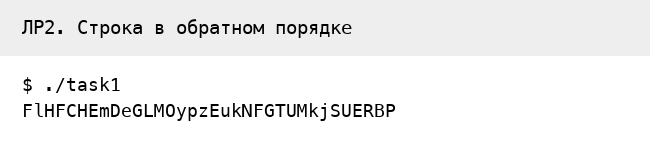

In [4]:
%%bash
set -e
cd Lab_2
fasm task1.asm task1.o >/dev/null
ld task1.o -o task1
echo '$ ./task1'
./task1

## 2. Матрица: 435 символов «!», 15 столбцов, 29 строк

In [5]:
%%writefile Lab_2/task2.asm
format ELF64
public _start
N = 435
M = 15
K = 29
section '.data' writable
    newline db 10
section '.bss' writable
    symbols rb N
section '.text' executable
_start:
    cld
    mov rdi, symbols
    mov ecx, N
    mov al, '!'
    rep stosb
    mov r12, symbols
    mov r13d, 1
.row:
    mov eax, 1
    mov edi, 1
    mov rsi, r12
    mov edx, M
    syscall
    add r12, M
    mov eax, 1
    mov edi, 1
    mov rsi, newline
    mov edx, 1
    syscall
    inc r13
    cmp r13, K
    jbe .row
    mov eax, 60
    xor edi, edi
    syscall

Writing Lab_2/task2.asm


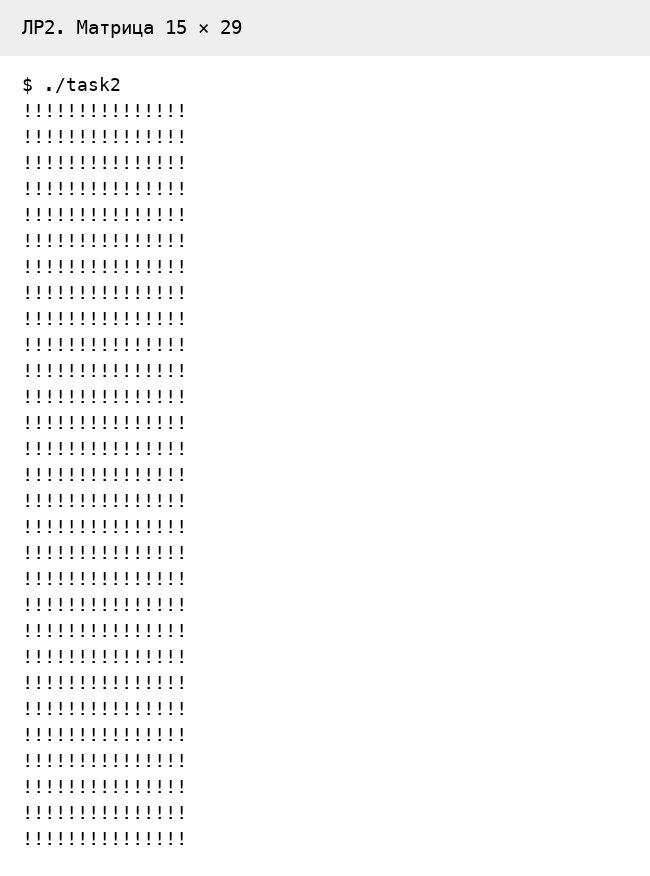

In [6]:
%%bash
set -e
cd Lab_2
fasm task2.asm task2.o >/dev/null
ld task2.o -o task2
echo '$ ./task2'
./task2

## 3. Треугольник: 435 символов «!», 29 строк

In [7]:
%%writefile Lab_2/task3.asm
format ELF64
public _start
N = 435
M = 15
K = 29
section '.data' writable
    newline db 10
section '.bss' writable
    symbols rb N
section '.text' executable
_start:
    cld
    mov rdi, symbols
    mov ecx, N
    mov al, '!'
    rep stosb
    mov r12, symbols
    mov r13d, 1
.row:
    mov eax, 1
    mov edi, 1
    mov rsi, r12
    mov rdx, r13
    syscall
    add r12, r13
    mov eax, 1
    mov edi, 1
    mov rsi, newline
    mov edx, 1
    syscall
    inc r13
    cmp r13, K
    jbe .row
    mov eax, 60
    xor edi, edi
    syscall

Writing Lab_2/task3.asm


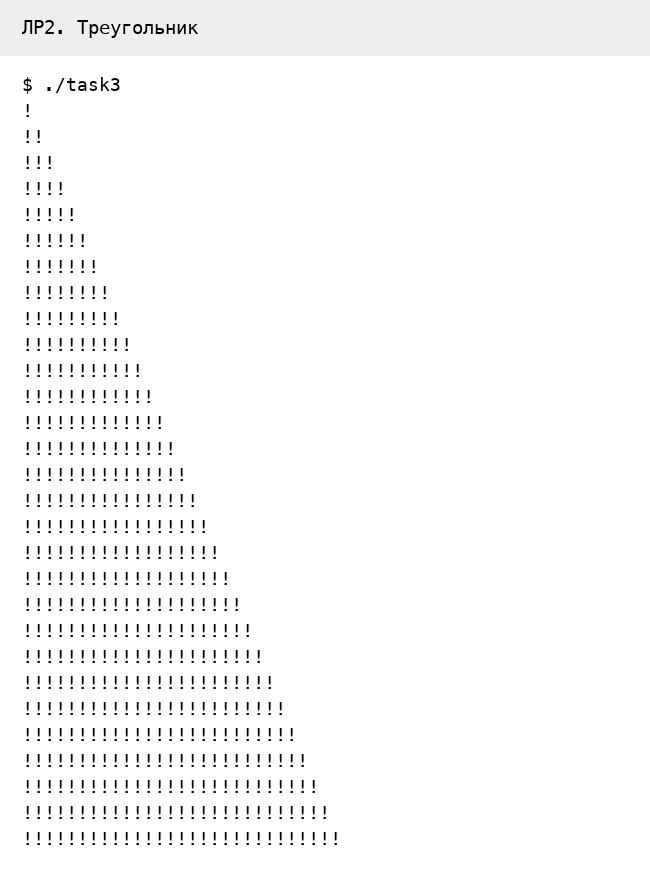

In [8]:
%%bash
set -e
cd Lab_2
fasm task3.asm task3.o >/dev/null
ld task3.o -o task3
echo '$ ./task3'
./task3

## 4. Сумма цифр числа 2269503710

In [9]:
%%writefile Lab_2/task4.asm
format ELF64
public _start
section '.bss' writable
buffer rb 32
section '.text' executable

_start:
    mov rax, 2269503710
    mov ebx, 10
    xor r8d, r8d
.sum:
    xor edx, edx
    div rbx
    add r8, rdx
    test rax, rax
    jnz .sum
    mov rax, r8
    mov rsi, buffer+31
    mov byte [rsi], 10
    mov ecx, 1
.decimal:
    xor edx, edx
    div rbx
    add dl, '0'
    dec rsi
    mov [rsi], dl
    inc rcx
    test rax, rax
    jnz .decimal
    mov rdx, rcx
    mov eax, 1
    mov edi, 1
    syscall
    mov eax, 60
    xor edi, edi
    syscall

Writing Lab_2/task4.asm


## 5. Версия на C и сокращение исполняемых файлов

In [10]:
%%writefile Lab_2/task5.c
#include <stdio.h>
#include <stdint.h>
int main(void) {
    uint64_t n = 2269503710ULL;
    unsigned sum = 0;
    do { sum += n % 10; n /= 10; } while (n);
    printf("%u\n", sum);
    return 0;
}

Writing Lab_2/task5.c


### Компактная версия FASM с непосредственным созданием ELF

In [11]:
%%writefile Lab_2/task4_min.asm
format ELF64 executable 3
entry _start
segment readable executable

_start:
    mov rax, 2269503710
    mov ebx, 10
    xor r8d, r8d
.sum:
    xor edx, edx
    div rbx
    add r8, rdx
    test rax, rax
    jnz .sum
    mov rax, r8
    mov rsi, buffer+31
    mov byte [rsi], 10
    mov ecx, 1
.decimal:
    xor edx, edx
    div rbx
    add dl, '0'
    dec rsi
    mov [rsi], dl
    inc rcx
    test rax, rax
    jnz .decimal
    mov rdx, rcx
    mov eax, 1
    mov edi, 1
    syscall
    mov eax, 60
    xor edi, edi
    syscall

segment readable writeable
buffer rb 32

Writing Lab_2/task4_min.asm


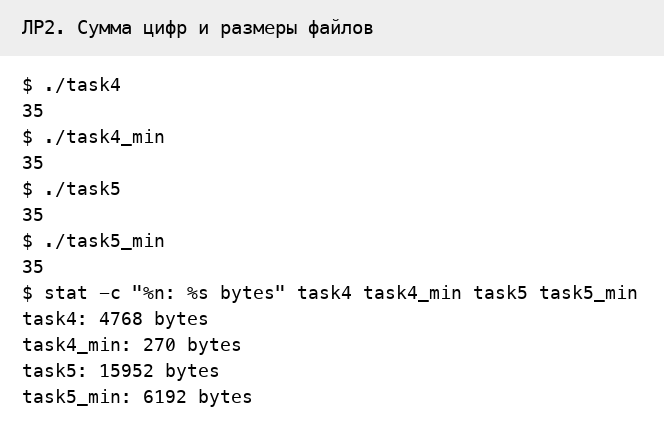

In [12]:
%%bash
set -e
cd Lab_2
fasm task4.asm task4.o >/dev/null
ld task4.o -o task4
fasm task4_min.asm task4_min >/dev/null
chmod +x task4_min
gcc -O0 task5.c -o task5
gcc -Os -s -fno-asynchronous-unwind-tables -Wl,--build-id=none,-z,noseparate-code task5.c -o task5_min
for p in task4 task4_min task5 task5_min; do
    echo "$ ./$p"
    ./$p
done
echo '$ stat -c "%n: %s bytes" task4 task4_min task5 task5_min'
stat -c '%n: %s bytes' task4 task4_min task5 task5_min

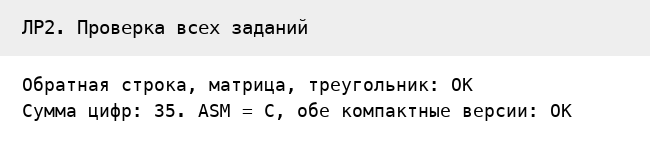

In [13]:
from pathlib import Path
import subprocess
p = Path('Lab_2').resolve()
def output(name):
    return subprocess.check_output([str(p/name)], text=True)
assert output('task1') == S[::-1]+'\n'
assert output('task2') == (D*M+'\n')*K
assert output('task3') == ''.join(D*k+'\n' for k in range(1,N1+1))
for name in ('task4','task4_min','task5','task5_min'):
    assert output(name) == str(sum(map(int,str(N4))))+'\n'
print('Обратная строка, матрица, треугольник: OK')
print('Сумма цифр: 35. ASM = C, обе компактные версии: OK')
assert sum(map(int,str(N4))) == 35